# 5.73

## a.

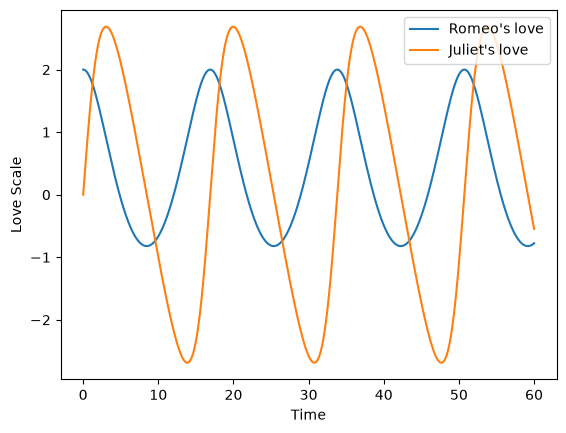

In [1]:
import numpy as np

# define the system of equations
def system(t, initial):
    alpha, beta, gamma = 0.2, 0.8, 0.1
    x, y = initial
    dxdt = -alpha*y
    dydt = beta*x - gamma*y**2
    return np.array([dxdt, dydt])

# RK4 method
def rk4(f, initial, t0, tmax, dt): # where f should be the system to be solved
    t = np.arange(t0, tmax + dt, dt)
    z = np.zeros((len(t), len(initial)))
    z[0] = initial
    for n in range(len(t) - 1):
        k1 = f(t[n], z[n])
        k2 = f(t[n] + dt / 2, z[n] + dt / 2 * k1)
        k3 = f(t[n] + dt / 2, z[n] + dt / 2 * k2)
        k4 = f(t[n] + dt, z[n] + dt * k3)
        z[n+1] = z[n] + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)   
    return t, z

# time from 0 to 60, with step of 0.01
t0 = 0
tmax = 60
dt = 0.01

# initial conditions
x0 = 2
y0 = 0
initial = np.array([x0, y0]) #2 variables x and y

# apply the RK4 method to solve the system
t, xy = rk4(system, initial, t0, tmax, dt)

# Extract values for x and y; first column is x and the second column is y
x, y = xy[:, 0], xy[:, 1]

import matplotlib.pyplot as plt
plt.plot(t, x, label = 'Romeo\'s love')
plt.plot(t, y, label = 'Juliet\'s love')
plt.xlabel('Time')
plt.ylabel('Love Scale')
plt.legend()
plt.show()

From the graph, the fate of their love show a periodic oscillation (like sin and cos function), which means there will never be a steady state for their love. That means their feelings for each other are not stable but never go to an extreme point like 5 or -5. Instead, Romeo's love for Juliet from 2 to -1 periodically, and similarly, Juliet's love for Romeo follows a oscillating pattern but displays more emotionally.

## b.

In [2]:
def system_with_gamma(t, initial, gamma): # make gamma is changeable
    alpha, beta = 0.2, 0.8
    x, y = initial
    dxdt = -alpha*y
    dydt = beta*x - gamma*y**2
    return np.array([dxdt, dydt])

def rk4_gamma(f, initial, t0, tmax, dt, gamma): # allow gamma to be a parameter
    t = np.arange(t0, tmax + dt, dt)
    z = np.zeros((len(t), len(initial)))
    z[0] = initial 
    for n in range(len(t) - 1):
        k1 = f(t[n], z[n], gamma)
        k2 = f(t[n] + dt / 2, z[n] + dt / 2 * k1, gamma)
        k3 = f(t[n] + dt / 2, z[n] + dt / 2 * k2, gamma)
        k4 = f(t[n] + dt, z[n] + dt * k3, gamma)
        z[n+1] = z[n] + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)    
    return t, z

def t30(gamma): # set the initial time is 0 and end at 30
    t, xy = rk4_gamma(system_with_gamma, initial, 0, 30, 0.01, gamma)
    return xy[-1, 1] # return the y value, where is suppose to be 0 for indifference at t = 30


# apply bisection method to find the gamma, which makes the value of y is close to 0 at t = 30
def Bisection(f, a, b, tol):
    if np.sign(f(a)) == np.sign(f(b)): # both f(a) and f(b) are above or below zero
        print("a and b do not bound a root.")
    m = (a+b)/2
    while (b - a) > tol:
        if np.abs(f(m)) < tol: # stopping condition
            return m
        elif np.sign(f(a)) == np.sign(f(m)):
            a = m # squeeze the interval to the right
        elif np.sign(f(m)) == np.sign(f(b)):
            b = m # squeeze the interval to the left
        elif f(a) == 0:
            return a
        elif f(b) == 0:
            return b
        m = (a+b)/2 # recalculate the midpoint
    return m

# Find the gamma value that y(t) = 0 where t = 30
gamma_indifference = Bisection(t30, 0.1, 4, 1e-8)
print(f'The approximated gamma value is {gamma_indifference}')

The approximated gamma value is 3.479074847698212


In [3]:
vals = t30(gamma_indifference)
print(f'value of Juliet\'s love is {vals} with the given gamma value {gamma_indifference}')


t_check, xy_check = rk4_gamma(system_with_gamma, initial, t0, 30, dt, gamma_indifference)
y_values_t30 = xy_check[-1, 1]
print(y_values_t30)

value of Juliet's love is -4.836351673743328e-09 with the given gamma value 3.479074847698212
-4.836351673743328e-09


If $\gamma = 3.479074847698212$, Juliet has a feeling of indifference at $t = 30$.

# 5.74 (a-b)

## a.
$x' = v_x$<br>
$v'_{x} = -\frac{x}{(\sqrt{x^2 + y^2})^3}$<br>
$y' = v_y$<br>
$v'_y = -\frac{y}{(\sqrt{x^2 + y^2})^3}$

In [4]:
# differential equations
def celestial_system(t, z):
    x, vx, y, vy = z
    r = np.sqrt(x**2 + y**2)
    dxdt = vx
    dvxdt = -x / r**3
    dydt = vy
    dvydt = -y / r**3
    return np.array([dxdt, dvxdt, dydt, dvydt])

## b.

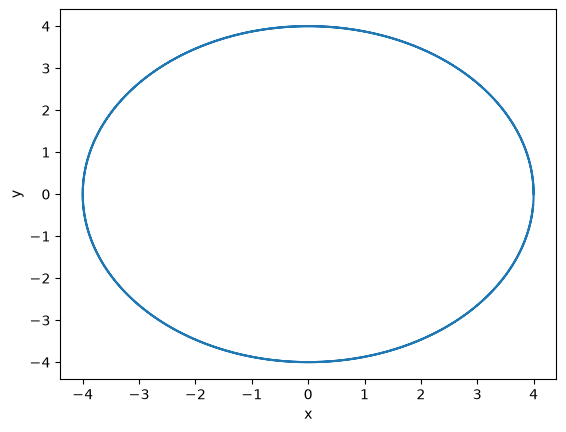

In [5]:
def rk4(f, initial, t0, tmax, dt):
    t = np.arange(t0, tmax + dt, dt)
    x = np.zeros((len(t), len(initial)))
    x[0] = initial   
    for n in range(len(t) - 1):
        k1 = f(t[n], x[n])
        k2 = f(t[n] + dt / 2, x[n] + dt / 2 * k1)
        k3 = f(t[n] + dt / 2, x[n] + dt / 2 * k2)
        k4 = f(t[n] + dt, x[n] + dt * k3)
        x[n+1] = x[n] + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4) 
    return t, x

t0 = 0
tmax = 100
dt = 0.01

# Initial conditions
x0 = 4
y0 = 0
vx0 = 0
vy0 = 0.5
initial_conditions = np.array([x0, vx0, y0, vy0])

# Solve the system using the RK4 method
t, solution = rk4(celestial_system, initial_conditions, t0, tmax, dt)

# plot
plt.plot(solution[:, 0], solution[:, 2])  # x vs y
plt.xlabel('x')
plt.ylabel('y')
plt.show()

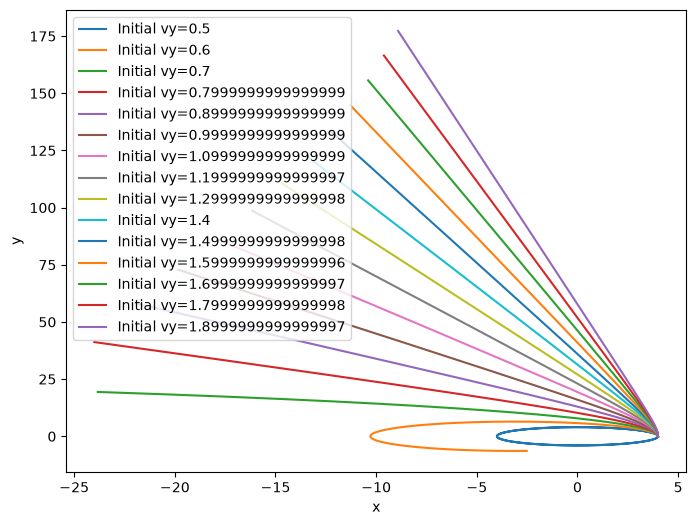

In [6]:
# changing initial vy
vy_initial_values = np.arange(0.5, 2, 0.1)
solutions = []
for vy0 in vy_initial_values:
    initial_conditions[3] = vy0  # different initial y velocity
    t, sol = rk4(celestial_system, initial_conditions, t0, tmax, dt)
    solutions.append(sol)
    
plt.figure(figsize=(8,6))
for i, sol in enumerate(solutions):
    plt.plot(sol[:, 0], sol[:, 2], label=f'Initial vy={vy_initial_values[i]}')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

# 5.76 

## a.
The unit for $\frac{dB}{dt}$ is $whales/year$. It represent the number of whales per year.<br>
The unit for $\frac{dK}{dt}$ is $\frac{tons}{arce}/year$. It represents the tons of krill per acre per year.


## b.

### For $\frac{dB}{dt}$:
- $-0.05B$ is the term which represents the natural decrease in the blue whale population. It should be negative because this is the natural loss of number of whales at a rate of $5\%$ a year.

- $\left(\frac{0.02}{500}\right)BK$ is a term which represents the increase in the blue whale population by preying krill. The consumption of krill will increase the number of whales. It should be positive since this rate contributes to growth of whales and is proportional to both the number whales and krill. More krill, more whales.

### For $\frac{dK}{dt}$
- $0.25 K$, this term shows the natural growth in the krill population density. It is positive because the krill population density grows at a rate of $25\%$ a year without any predators.

- $\left(\frac{0.02}{500}\right)BK$ represents the decrease in the krill population since whales are eating them. It is negative as the loss to the krill population and is proportional to both the krill population density and the number whales. More whales, less krill.

## c.

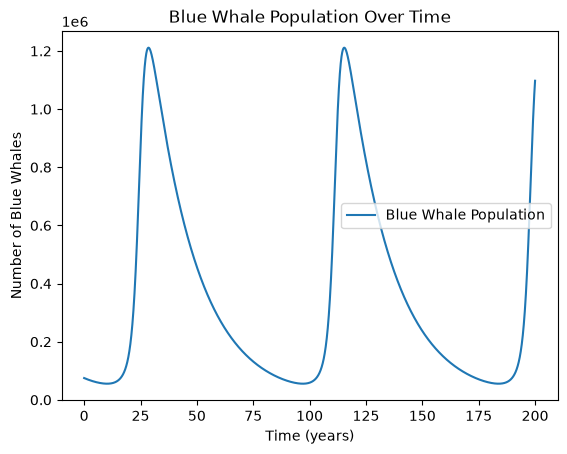

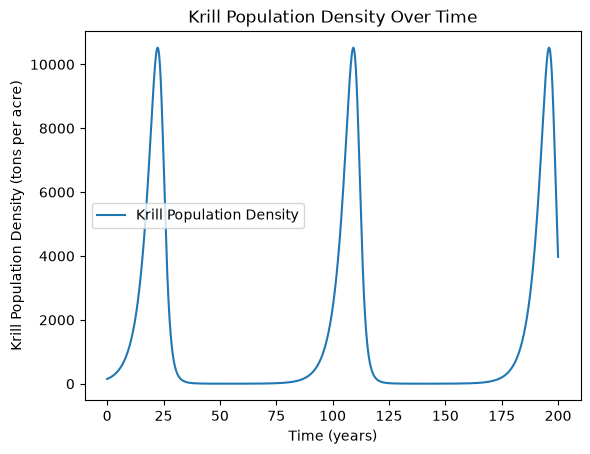

In [7]:

# model for blue whales and krill
def whale_krill(t, z):
    B, K = z
    dBdt = -0.05 * B + (0.02 / 500) * B * K
    dKdt = 0.25 * K - (0.10 / 150000) * B * K
    return np.array([dBdt, dKdt])

# RK4 method
def rk4(f, initial, t0, tmax, dt):
    t = np.arange(t0, tmax + dt, dt)
    x = np.zeros((len(t), len(initial)))
    x[0] = initial
    for n in range(len(t) - 1):
        k1 = f(t[n], x[n])
        k2 = f(t[n] + dt / 2, x[n] + dt / 2 * k1)
        k3 = f(t[n] + dt / 2, x[n] + dt / 2 * k2)
        k4 = f(t[n] + dt, x[n] + dt * k3)
        x[n+1] = x[n] + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4) 
    return t, x

# Initial conditions
B0 = 75000
K0 = 150
initial_conditions = np.array([B0, K0])
t0 = 0
tmax = 200
dt = 0.01

# using the RK4 method
t, sol = rk4(whale_krill, initial_conditions, t0, tmax, dt)

# Plotting the solution
# Plot B(t), the blue whale population
plt.plot(t, sol[:, 0], label='Blue Whale Population')
plt.title('Blue Whale Population Over Time')
plt.xlabel('Time (years)')
plt.ylabel('Number of Blue Whales')
plt.legend()
plt.show()

# Plot K(t), the krill population density
plt.plot(t, sol[:, 1], label='Krill Population Density')
plt.title('Krill Population Density Over Time')
plt.xlabel('Time (years)')
plt.ylabel('Krill Population Density (tons per acre)')
plt.legend()
plt.show()

## d.

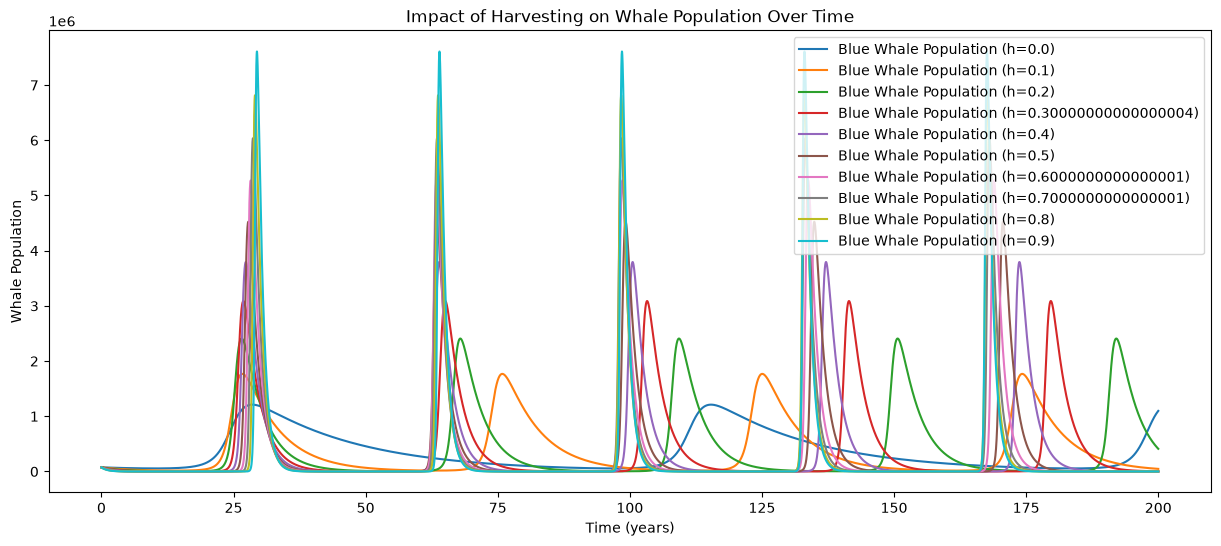

In [8]:
h = np.arange(0, 1, 0.1) # Harvesting rate: number of whales harvested per year
harvesting = []

# Initial conditions
B0 = 75000
K0 = 150
initial_conditions = np.array([B0, K0])
t0 = 0
tmax = 200
dt = 0.01

# include the harvesting term.
def whale_krill_harvest(harvest):
    def model(t, z):
        B, K = z
        dBdt = -0.05 * B + (0.02 / 500) * B * K - harvest * B
        dKdt = 0.25 * K - (0.10 / 150000) * B * K
        return np.array([dBdt, dKdt])
    return model
    
for harvest in h: 
    # the model function for the current harvest rate
    model = whale_krill_harvest(harvest)
    
    # using the RK4 method with the current harvesting rate
    t, sols = rk4(model, initial_conditions, t0, tmax, dt)
    harvesting.append(sols)   

plt.figure(figsize = (15,6))
for i, sol in enumerate(harvesting):
    plt.plot(t, sol[:, 0], label=f'Blue Whale Population (h={h[i]})')
plt.title('Impact of Harvesting on Whale Population Over Time')
plt.xlabel('Time (years)')
plt.ylabel('Whale Population')
plt.legend()
plt.show()

# 5.79

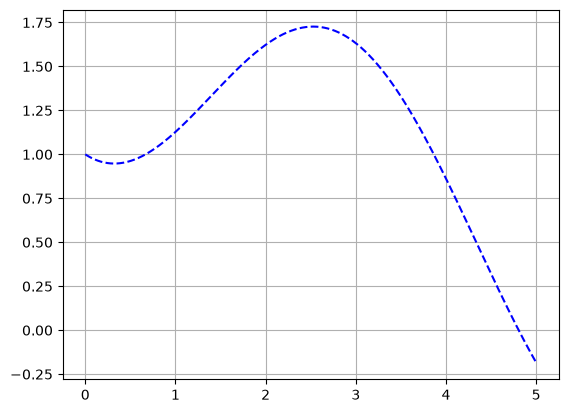

In [9]:
import scipy.integrate

# define the ODE 
f = lambda x, t: -(1/3.0)*x + np.sin(t)

x0 = 1 # initial condition for x at t = 0

# an array of time from 0 to 5 with 1000 points
t = np.linspace(0,5,1000)

# apply odeint to solve 
x = scipy.integrate.odeint(f,x0,t)

# plot the solutions for x over time
plt.plot(t,x[:,0],'b--')
plt.grid()
plt.show()

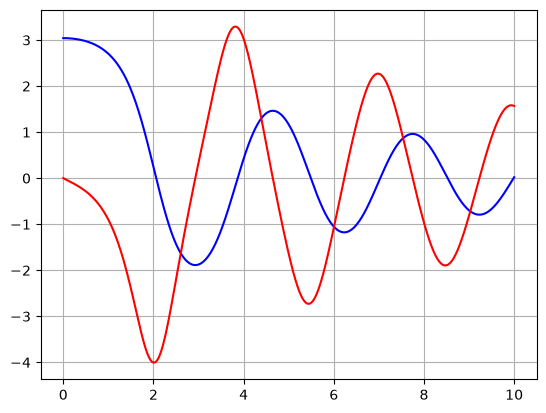

In [10]:

import scipy.integrate

# the lambda function of the ODE system
# x represents a vector of solutions, and x[0] is the angle, x[1] is the angular velocity
F = lambda x, t, b, c: [x[1] , -b*x[1] - c*np.sin(x[0])]

# initial conditions for [angle, angular velocity]
x0 = [np.pi - 0.1 , 0]

# time array from 0 to 10 with 1000 points
t = np.linspace(0,10,1000)

# parameter for ODEs, b and c
b = 0.25
c = 5

# apply odeint to solve the ODE system, with passing arguments of b and c
x = scipy.integrate.odeint(F, x0, t, args=(b, c))

# plot the solutions of angle (in blue) and angular velocity (in red) over time
plt.plot(t,x[:,0],'b', t,x[:,1],'r')
plt.grid()
plt.show()

## a. Code comments shown above.

## b.
The initial condition are $x(0) = \pi - 0.1$ and $y(0) = 0$. $x$ represents the angle which means that he pendulum system starts from a vertically downward equilibrium position with a radian of 0.1. $y$ gives the angular velocity and there is no initial motion since zero.

## c.
Logistic equation: https://www.sciencedirect.com/topics/computer-science/logistic-equation#:~:text=Sometimes%20the%20Logistic%20equation%20is,is%20called%20the%20carrying%20capacity.

$\frac{dP}{dt} = rP\left(1-\frac{P}{K}\right)$

$P$ is the population size<br>
$r$ is the growth rate<br>
$K$ is the capacity in ecology

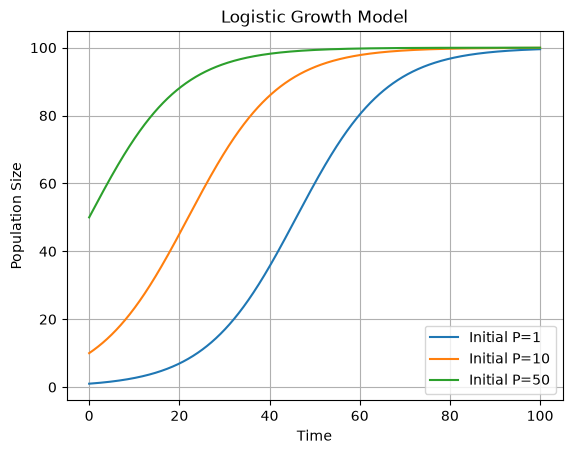

In [11]:
from scipy.integrate import odeint

# Logistic growth model function
def logistic_growth(P, t, r, K):
    dPdt = r * P * (1 - P / K)
    return dPdt

# Parameters
r = 0.1  # growth rate
K = 100  # capacity

# Time points
t = np.linspace(0, 100, 1000)

# initial conditions
initial_conditions = [1, 10, 50] 

# Solve the ODE for each initial condition
for P0 in initial_conditions:
    P = odeint(logistic_growth, P0, t, args=(r, K))
    plt.plot(t, P, label=f'Initial P={P0}')

# Plot
plt.title('Logistic Growth Model')
plt.xlabel('Time')
plt.ylabel('Population Size')
plt.legend()
plt.grid(True)
plt.show()


## d.
$\frac{dP}{dt} = rP\left(1-\frac{P}{K}\right)$<br>
$P(t) = \frac{P_0K}{P_0 + (K - P_0)e^{-rt}}$

[0.001 0.101 0.201 0.301 0.401 0.501 0.601 0.701 0.801 0.901]


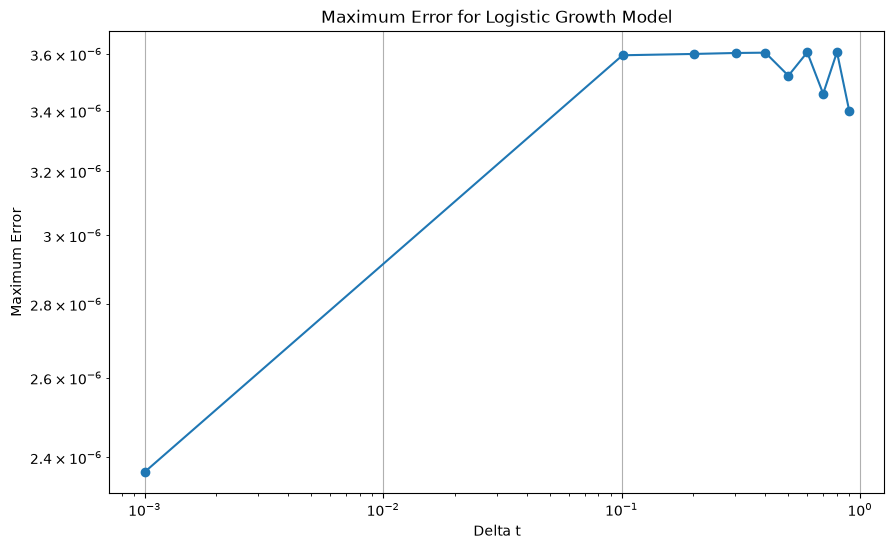

In [12]:
from scipy.integrate import odeint

# Define the ODE for the logistic growth model
def logistic_growth(P, t, r, K):
    dPdt = r * P * (1 - P / K)
    return dPdt

P0 = 10  # initial population size

# analytical solution with the initial value
def analytical_solution(P0, t, r, K):
    return (P0 * K) / (P0 + (K - P0) * np.exp(-r * t))

# Parameters
r = 0.1  # growth rate
K = 100  # capacity

# time steps, delta t
time_steps = np.arange(0.001, 1, 0.1)
print(time_steps)

# maximum error for each time step
max_errors = []

for dt in time_steps:
    # time array
    t = np.arange(0, 100, dt)
    
    # using odeint
    P_numerical = odeint(logistic_growth, P0, t, args=(r, K))
    
    # analytical solution
    P_analytical = analytical_solution(P0, t, r, K)
    
    # absolute error
    errors = np.abs(P_numerical[:, 0] - P_analytical)
    
    # record the maximum error
    max_error = np.max(errors)
    max_errors.append(max_error)
    
    # plot the numerical and analytical solutions
    #plt.plot(t, P_numerical[:, 0], 'b--', label=f'Numerical (dt={dt})')
    #plt.plot(t, P_analytical, 'r-', label='Analytical')
    #plt.legend()
    #plt.show()

# Plot the relationship between time step and maximum error
plt.figure(figsize=(10, 6))
plt.plot(time_steps, max_errors, 'o-')
plt.title('Maximum Error for Logistic Growth Model')
plt.xlabel('Delta t')
plt.ylabel('Maximum Error')
plt.xscale('log')
plt.yscale('log')
plt.grid(True)
plt.show()

The time steps, $\Delta t$, are given $[0.001 0.101 0.201 0.301 0.401 0.501 0.601 0.701 0.801 0.901]$. From the maximum error plot using a logarithmic scale, as the time step increases, the maximum error first increases but then decreases/becomes unstable again. This is what we expect as a smaller $\Delta t$ usually perform a more accurate numerical solution with more captured details. 

## e.

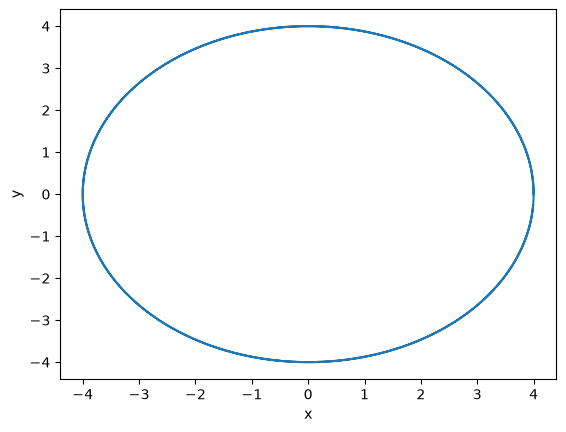

In [13]:
# differential equations
def celestial_system(z, t):
    x, vx, y, vy = z
    r = np.sqrt(x**2 + y**2)
    dxdt = vx
    dvxdt = -x / r**3
    dydt = vy
    dvydt = -y / r**3
    return [dxdt, dvxdt, dydt, dvydt]

t = np.linspace(0, 100, 10000)

# Initial conditions
x0 = 4
y0 = 0
vx0 = 0
vy0 = 0.5
z0 = [x0, vx0, y0, vy0]

# Solve the system using the RK4 method
z = scipy.integrate.odeint(celestial_system, z0, t)

# plot
plt.plot(z[:, 0], z[:, 2])  # x vs y
plt.xlabel('x')
plt.ylabel('y')
plt.show()